# Лабораторная работа 2. Кластеризация методом k-means

*Студентка:* Барашкова Альбина Станиславовна <br>
*Цель:* Сегментировать потребителей леденцов на основе мотивов их потребления с помощью кластеризации методом k-mean для последующего формирования маркетинговых стратегий.<br>
*Гипотеза:* Потребительская аудитория неоднородна и разделяется на 3-4 устойчивых сегмента <br>

In [70]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


In [71]:
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import davies_bouldin_score


In [72]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Отключаем UserWarning от sklearn
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

In [73]:
df = pd.read_csv('Леденцы.dat', sep =';')

In [74]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [75]:
df.shape

(338, 11)

In [76]:
df = df.reset_index(drop = True)

Все признаки V1–V11 находятся на сопоставимых шкалах  (баллы от 1 до 5), и ни один из них не имеет существенно большего числового масштаба, чем остальные, поэтому стандартизация не нужна.<br>
Пропусков и выбросов нет <br>

In [77]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [78]:
feature_cols = ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11']
X = df[feature_cols].values

### Выбор кол-ва кластеров

Метод k-means требует заранее задать кол-во кластеров. Для того, чтобы его определить, отрисуем график каменистой осыпи и расчитаем кф силуэта. Будем перебирать кол-во кластеров в диапазоне [1;10]

#### 1. Каменистая осыпь

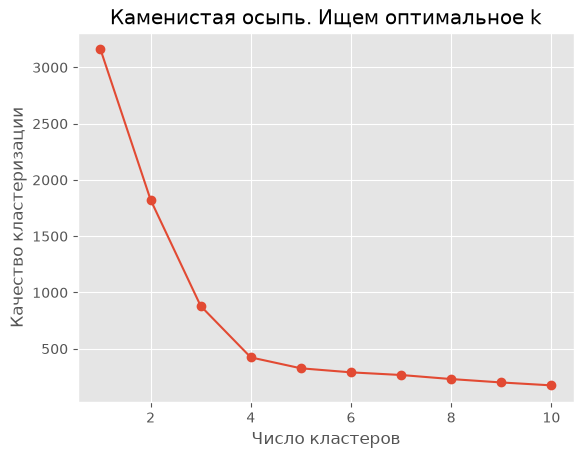

In [79]:
K = range(1, 11)

models = [KMeans(n_clusters = k, random_state=42, n_init = 10, verbose = 0).fit(df) for k in K]

dist = [model.inertia_ for model in models]

plt.plot(K, dist, marker = 'o')

# Строим 10 моделей с числом кластеров от 1 до 10. 
K = range(1, 11)
plt.xlabel('Число кластеров')
plt.ylabel('Качество кластеризации')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()


model.inertia_ - это сумма квадратов расстояний от каждой точки данных до ближайшего к ней центроида <br>
При увеличении числа кастеров инерция уменьшается. Выбираем такое значение k, после которого инерция перестает резко падать <br>
В нашем случае по графику каменистой осыпи k=4

#### 2.Коэффициент силуэта

Силуэт сравнивает две дистанции для каждой точки: среднее расстояние до своих соседей по кластеру, обозначаемое a(i), и наименьшее среднее расстояние до объектов другого кластера, обозначаемое b(i). Силуэт равен (b−a)/max(a,b).  

Значения лежат примерно в диапазоне $[-1,1]$:

- близко к `1` — точка хорошо лежит внутри своего кластера;
- около `0` — граница кластеров;
- отрицательное — возможно, точка ближе к чужому кластеру.

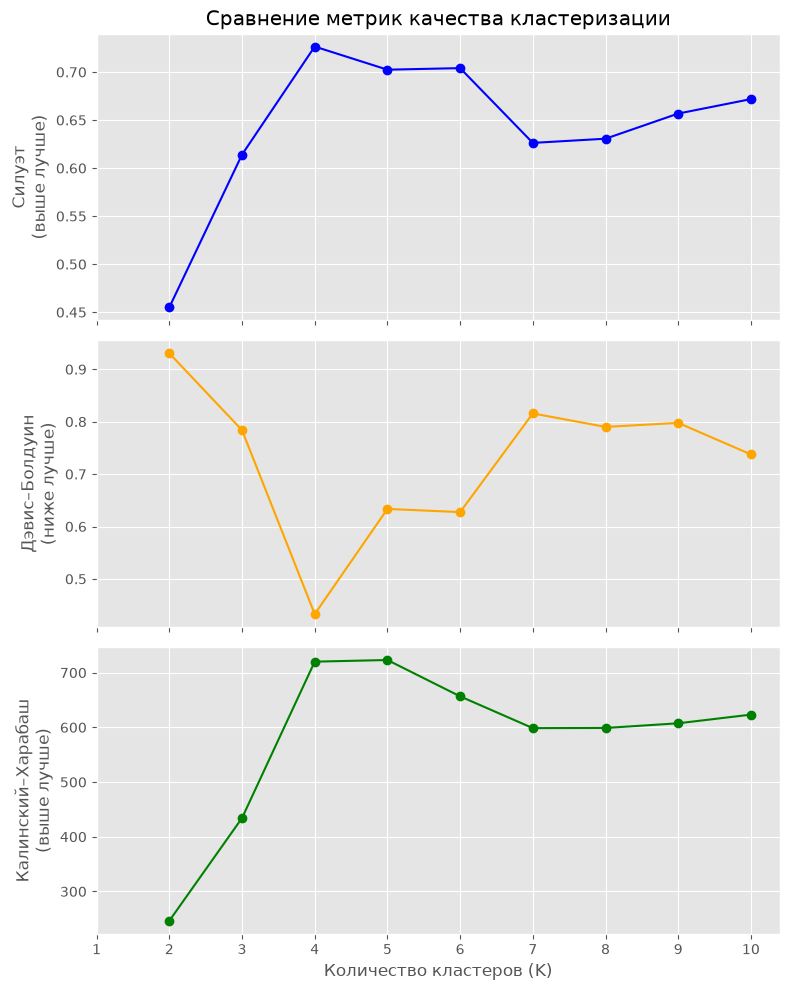

In [80]:
rows = []

for k in range(2, 11):
    model = KMeans(n_clusters = k, random_state =42, n_init=10)
    labels = model.fit_predict(X)
    rows.append({
        'K':k,
        'silhouette': silhouette_score(df, labels),  # силуэт. Чем выше, тем лучше. Одновременно учитывает компактность и разделённость.
        'davies_bouldin':davies_bouldin_score(df, labels), # Индекс Дэвиса–Болдуина (ниже лучше). Штрафует за большие внутрикластерные разбросы относительно расстояний между центрами. 
        'calinski_harabasz':calinski_harabasz_score(df, labels), # Индекс Калинского-Харабаша (выше лучше). Сравнивает межкластерный разброс с внутрикластерным, с поправкой на количество кластеров.
    })

df_scores = pd.DataFrame(rows)

# Строим 3 графика на одном холсте, чтобы масштабы не мешали друг другу
fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# 1. Силуэт
axes[0].plot(df_scores['K'], df_scores['silhouette'], marker='o', color='b')
axes[0].set_ylabel('Силуэт\n(выше лучше)')
axes[0].grid(True)
axes[0].set_title('Сравнение метрик качества кластеризации')

# 2. Индекс Дэвиса-Болдуина
axes[1].plot(df_scores['K'], df_scores['davies_bouldin'], marker='o', color='orange')
axes[1].set_ylabel('Дэвис–Болдуин\n(ниже лучше)')
axes[1].grid(True)

# 3. Индекс Калинского-Харабаша
axes[2].plot(df_scores['K'], df_scores['calinski_harabasz'], marker='o', color='g')
axes[2].set_ylabel('Калинский–Харабаш\n(выше лучше)')
axes[2].set_xlabel('Количество кластеров (K)')
axes[2].grid(True)

# Общие настройки оси X
plt.xticks(list(K))
plt.tight_layout()
plt.show()


1. Силуэт. Чем выше, тем лучше. Одновременно учитывает компактность и разделённость. <br>
2. Индекс Дэвиса–Болдуина (ниже лучше). Штрафует за большие внутрикластерные разбросы относительно расстояний между центрами. <br>
3. Индекс Калинского-Харабаша (выше лучше). Сравнивает межкластерный разброс с внутрикластерным, с поправкой на количество кластеров. <br>

Кф силуэта наивысший при 4 кластерах <br>
Индекс Дэвиса-Болдуина самый низкий при 4 кластерах <br>
Индекс Калинского-Харабаша самый высокий при 4-5 кластерах <br>

3/4 метрик указывают на 4 кластера, остановимся на этом кол-ве

### Кластеризация методом k-means

In [81]:
model = KMeans(n_clusters = 4, random_state = 42, max_iter =100, n_init=10, verbose =0)
labels = model.fit(df)
df['cluster'] = model.labels_

In [90]:
print('Инерция:', round(model.inertia_, 2))
print('Число итераций до сходимости:', model.n_iter_)

Инерция: 423.14
Число итераций до сходимости: 2


n_init = 10 заставляет алгоритм спуститься 10 раз с разных стартовых позиций и выбрать вариант, у которого наименьшая инерция. Это нужно для того, чтобы изначально не попасть в локальный минимум с плохим разделением <br>

max_iter =100 - максимальное число шагов пересчета центроидов. В нашей задаче алгоритм сошелся за 2 итерации, так как группы контрастные <br>

In [82]:
df.groupby('cluster').size()

cluster
0    108
1     61
2    110
3     59
dtype: int64

In [83]:
#центроиды
centroids = model.cluster_centers_

# расстояние от точки до центроида ее кластера
distance_to_center = []
for i in range(len(X)):
    points = X[i]
    cluster_idx = df['cluster'].iloc[i]
    center = centroids[cluster_idx]
    dist = np.linalg.norm(points - center) # Евклидово расстояние
    distance_to_center.append(dist)

df['distance_to_center'] = distance_to_center

In [84]:
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'cluster', 'distance_to_center'],
      dtype='str')

In [85]:
# центры кластеров
pd.DataFrame(centroids, columns=['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11'])

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
1,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000


In [86]:
density_df = df.groupby('cluster').agg(
    Размер=('cluster', 'count'),
    Среднее_расстояние=('distance_to_center', 'mean'),
    Медианное_расстояние=('distance_to_center', 'median'),
    Максимальное_расстояние=('distance_to_center', 'max')
).reset_index()

print('Оценка плотности кластеров')
display(density_df)

print('Среднее расстояние по всей выборке:',
      df['distance_to_center'].mean())

Оценка плотности кластеров


,cluster,Размер,Среднее_расстояние,Медианное_расстояние,Максимальное_расстояние
0,0,108,1.385038,1.434677,2.854977
1,1,61,0.830196,0.481309,1.610066
2,2,110,0.849202,0.753449,2.257202
3,3,59,0.374534,0.183333,2.062511


Среднее расстояние по всей выборке: 0.9341296111740245


Выводы по таблице плотности: <br>
Кластер 3 самый плотный. У него наименьшее среднее и медианное расстояние. Потребители этого мегмента мыслят практически одинаково.  <br>
Кластеры 1 и 2 имеют средние расстояния ниже среднего по выборке, это сегменты с минимальным внутренним разбросом. <br>
Кластер 0 имеет наибольшее среднее расстояние, т.е. самый ширвокий сегмент. Люди покупают леденцы при простуде по разным причинам, вариативность ответов выше <br>

Вычисленные евклидовы расстояния от объектов до центроидов это абсолютные величины в 11-мерном признаковом пространстве. Среднее расстояние по выборке составило 0.93 балла, что при 5-балльной шкале говорит о высокой компактности найденных кластеров.

### Визуализация, PCA

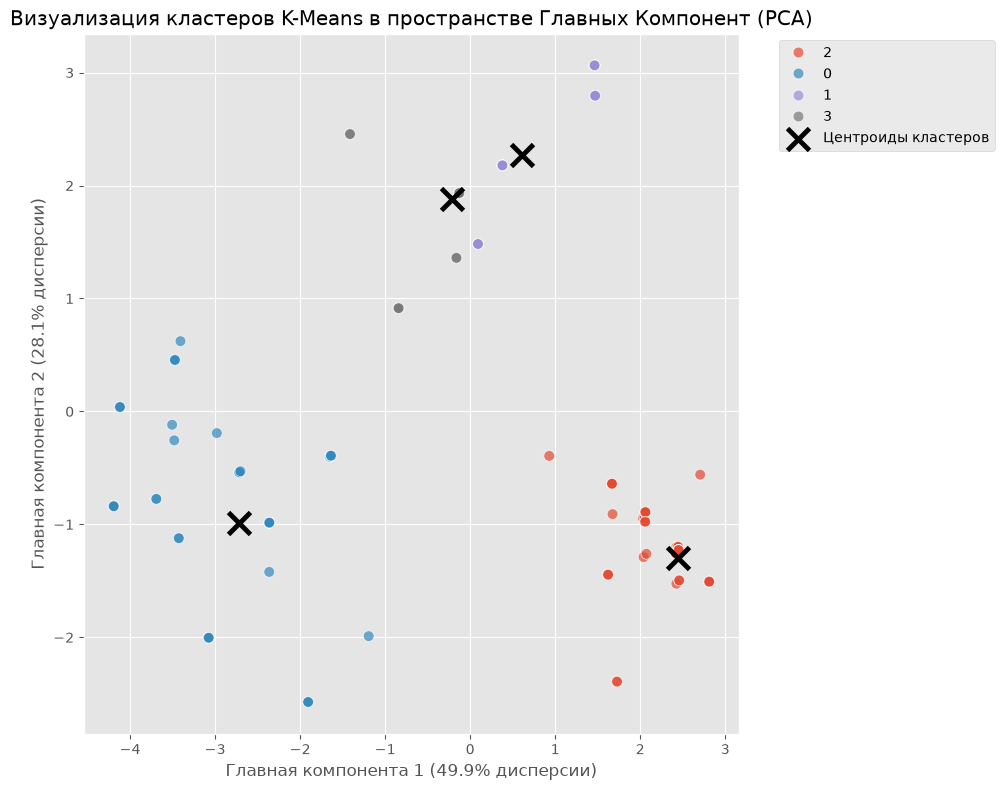

In [87]:
# Применяем PCA, сжимаем 11 измерений в 2
pca = PCA(n_components = 2, random_state = 42)
X_pca = pca.fit_transform(X)

# Проецируем центроиды в то же пространство PCA
centroid_pca = pca.transform(centroids)

pca_df = pd.DataFrame(X_pca, columns = ['PC_1', "PC_2"])
pca_df['cluster'] = df['cluster'].astype(str)

# График
plt.figure(figsize=(10,8))

sns.scatterplot(data = pca_df, x ='PC_1', y = 'PC_2', hue = 'cluster',
               alpha = 0.7, s =60,)

plt.scatter(centroid_pca[:, 0], centroid_pca[:, 1], marker ='x', s =250, linewidth = 3.5, color = 'black',
           label = 'Центроиды кластеров', zorder = 10)

plt.title(
    'Визуализация кластеров K-Means в пространстве Главных Компонент (PCA)'
)
plt.xlabel(
    f'Главная компонента 1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)'
)
plt.ylabel(
    f'Главная компонента 2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)'
)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

### Таблица профилей + тепловая карта

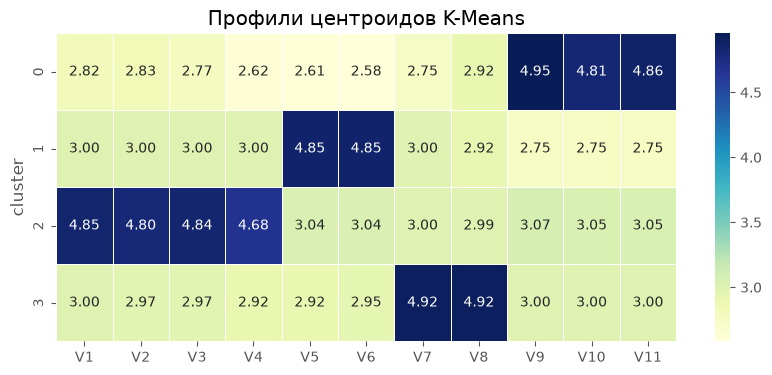

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
1,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000


In [88]:
# Средние оценки по 11 утверждениям
profiles = df.drop(columns=['distance_to_center']).groupby('cluster').mean()

plt.figure(figsize=(10, 4))
sns.heatmap(profiles, annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title('Профили центроидов K-Means')
plt.show()

display(profiles)